# Severe hematologic toxicity after day 28 — CALGB 40603 landmark analysis

**Outcome.** First grade ≥3 neutropenia, leukopenia, thrombocytopenia or febrile neutropenia (CTCAE v3.0) with onset after day 28, among patients free of such an event on or before day 28.

**Predictors.** 19 baseline variables and 18 adverse-event (AE) summaries restricted to AEs with onset ≤ day 28.

**Evaluation.** Nested cross-validation (5 outer × 4 inner stratified folds, seeds 1, 42, 2024). Imputation, scaling, encoding, resampling, feature reduction, hyperparameters, model family, decision threshold and risk-tier cut-points are all fitted on training folds only.

## 0. Setup

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, OneHotEncoder, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, f1_score,
                             fbeta_score, brier_score_loss)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline          # allows resampling steps inside the CV pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

TARGET   = "heme"
DATA     = "data"
LANDMARK = 28                         # days from registration
SEEDS    = [1, 42, 2024]
N_OUTER, N_INNER = 5, 4
ROB_SEEDS = [7, 99, 314, 777, 2025]   # unseen seeds for the robustness check
T0 = time.time()

## 1. Data

`treated2.csv` (one row per patient) and `aeclean.csv` (one row per AE) are used as distributed by Project Data Sphere. Code 9 (unknown) in grade and clinical T/N is treated as missing. AEs without a grade or onset day are dropped.

In [2]:
patients = pd.read_csv(f"{DATA}/treated2.csv")
ae = pd.read_csv(f"{DATA}/aeclean.csv")
for c in ["GRADE", "clinicalt", "clinicaln"]:
    patients[c] = patients[c].replace(9, np.nan)
ae = ae[ae.GRADE_ID.between(1, 5) & ae.aestart.notna()].copy()

HEME = {"Neutropenia": "Neutrophils/granulocytes (ANC/AGC)",
        "Leukopenia": "Leukocytes (total WBC)",
        "Thrombocytopenia": "Platelets"}
ae["htype"] = ae.EVENTNAME.map({v: k for k, v in HEME.items()})
ae.loc[ae.EVENTNAME.str.startswith("Febrile neutropenia"), "htype"] = "Febrile neutropenia"
TYPES = ["Neutropenia", "Leukopenia", "Febrile neutropenia", "Thrombocytopenia"]

# toxicity groups used only for early-AE features (first matching rule wins)
GROUP_RULES = [
    ("Neutropenia",      ae.EVENTNAME.isin(["Neutrophils/granulocytes (ANC/AGC)", "Leukocytes (total WBC)"])),
    ("Febrile neutropenia", ae.EVENTNAME.str.startswith("Febrile neutropenia")),
    ("Thrombocytopenia", ae.EVENTNAME.eq("Platelets")),
    ("Anemia",           ae.EVENTNAME.eq("Hemoglobin")),
    ("Infection",        ae.CATEGORY.eq("INFECTION")),
    ("Fatigue",          ae.EVENTNAME.str.startswith("Fatigue")),
    ("Hypertension",     ae.EVENTNAME.eq("Hypertension")),
    ("Neuropathy",       ae.EVENTNAME.str.startswith("Neuropathy:")),
    ("GI",               ae.CATEGORY.eq("GASTROINTESTINAL")),
    ("Pain",             ae.CATEGORY.eq("PAIN")),
    ("Metabolic_lab",    ae.CATEGORY.eq("METABOLIC/LABORATORY")),
    ("Thrombosis",       ae.EVENTNAME.str.startswith("Thrombosis")),
]
ae["group"] = None
for name, mask in GROUP_RULES:
    ae.loc[mask & ae.group.isna(), "group"] = name
GROUPS = ["Neutropenia", "Thrombocytopenia", "Fatigue", "GI", "Neuropathy", "Pain", "Infection", "Hypertension", "Metabolic_lab"]
print(len(patients), "patients |", len(ae), "adverse events")

443 patients | 15372 adverse events


## 2. Features

Baseline variables are known before treatment (the randomized arm included). Early-AE features use only AEs with onset ≤ day 28. Dose modifications and doses received are not used: they are determined after the landmark.

In [3]:
BASE = ["AGE_C", "WHITE", "GRADE", "clinicalt", "clinicaln", "er", "pgr", "histotype", "meno", "her2fish", "her2ihc",
        "tsizepe", "tsizemamm", "tsizeultra", "tsizemri", "indrx", "factora", "factorb", "stra1_stage"]
CATEGORICAL = ["indrx", "WHITE", "histotype", "GRADE", "clinicalt", "clinicaln", "meno", "er", "pgr", "her2ihc", "AGE_C", "stra1_stage"]

def early_features(L):
    e = ae[ae.aestart <= L]
    f = e.groupby("MASK_ID").agg(e_count=("EVENTNAME", "count"),
                                 e_max_grade=("GRADE_ID", "max"),
                                 e_n_types=("EVENTNAME", "nunique"),
                                 e_first_day=("aestart", "min"))
    f["e_count_g2"] = e[e.GRADE_ID >= 2].groupby("MASK_ID").size()
    for g in GROUPS:
        f["e_max_" + g.lower()] = e[e.group == g].groupby("MASK_ID").GRADE_ID.max()
    for t in TYPES:
        f["e_max_" + t.split(" ")[0].lower() + "_h"] = e[e.htype == t].groupby("MASK_ID").GRADE_ID.max()
    X = patients[["MASK_ID"] + BASE].merge(f.reset_index(), on="MASK_ID", how="left")
    early = [c for c in X.columns if c.startswith("e_")]
    zero = [c for c in early if c != "e_first_day"]
    X[zero] = X[zero].fillna(0)                        # no AE by day L -> count/grade 0
    X["e_first_day"] = X["e_first_day"].fillna(L + 1)  # no AE by day L -> "after the window"
    return X, early

X_all, EARLY = early_features(LANDMARK)
FEATURES = BASE + EARLY
print(len(BASE), "baseline +", len(EARLY), "early-AE features =", len(FEATURES))

19 baseline + 18 early-AE features = 37


## 3. Landmark cohort and outcome

Patients whose first qualifying grade ≥3 event occurred on or before day 28 are excluded (outcome already known). Among the rest, y = 1 if the first event occurred after day 28, otherwise 0.

In [4]:
if TARGET == "heme":
    ev = ae[ae.htype.notna() & (ae.GRADE_ID >= 3)]
else:
    ev = ae[ae.GRADE_ID >= 3]
first = ev.groupby("MASK_ID").aestart.min()
t = X_all.MASK_ID.map(first)
d = X_all[~(t <= LANDMARK)].copy().reset_index(drop=True)
d["y"] = d.MASK_ID.map(first).gt(LANDMARK).astype(int)
d["carbo"] = d.indrx.isin([3, 4]).astype(int)       # arms 3-4 include carboplatin
X, y = d[FEATURES], d.y.values
print("Patients at risk:", len(d))
print("Events (y=1):", y.sum(), f"({y.mean():.1%})", "| no event (y=0):", (y == 0).sum())
print("Excluded (event on or before day 28):", len(X_all) - len(d))
print(pd.crosstab(d.carbo.map({0: "no carboplatin", 1: "carboplatin"}), d.y, margins=True))

Patients at risk: 366
Events (y=1): 134 (36.6%) | no event (y=0): 232
Excluded (event on or before day 28): 77
y                 0    1  All
carbo                        
carboplatin      70   90  160
no carboplatin  162   44  206
All             232  134  366


Descriptive only (not used for feature selection):

In [5]:
desc = pd.DataFrame({"missing": X.isna().mean().round(2),
                     "mean (y=0)": X[y == 0].mean().round(2),
                     "mean (y=1)": X[y == 1].mean().round(2)})
desc

,missing,mean (y=0),mean (y=1)
AGE_C,0.00,1.90,1.99
WHITE,0.00,1.26,1.30
GRADE,0.11,2.85,2.83
clinicalt,0.01,2.08,2.15
clinicaln,0.05,0.68,0.69
er,0.01,1.08,1.04
pgr,0.02,1.03,1.05
histotype,0.01,1.25,1.25
meno,0.01,0.45,0.46
her2fish,0.67,1.23,1.25


## 4. Evaluation utilities

### 4.1 Metrics

In [6]:
def metrics(y_true, prob, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(AUC=roc_auc_score(y_true, prob),
                PR_AUC=average_precision_score(y_true, prob),
                Accuracy=(tp + tn) / len(y_true),
                Sensitivity=tp / max(tp + fn, 1),
                Specificity=tn / max(tn + fp, 1),
                Precision=tp / max(tp + fp, 1),
                NPV=tn / max(tn + fn, 1),
                F1=f1_score(y_true, pred, zero_division=0),
                F2=fbeta_score(y_true, pred, beta=2, zero_division=0),
                Brier=brier_score_loss(y_true, np.clip(prob, 0, 1)),
                TN=tn, FP=fp, FN=fn, TP=tp)

### 4.2 Threshold selection

Default rule: Youden's J, which balances sensitivity and specificity; F2, F1, accuracy and a sensitivity ≥0.80 rule are compared in Section 14. The threshold is always chosen on inner out-of-fold probabilities of the training portion.

In [7]:
def choose_threshold(y_tr, p_tr, rule="youden"):
    grid = np.unique(np.round(p_tr, 4))
    best_t, best_s = 0.5, -np.inf
    for t in grid:
        pr = (p_tr >= t).astype(int)
        tp = ((pr == 1) & (y_tr == 1)).sum(); tn = ((pr == 0) & (y_tr == 0)).sum()
        sens, spec = tp / y_tr.sum(), tn / (y_tr == 0).sum()
        if rule == "youden": s = sens + spec - 1
        elif rule == "f2":   s = fbeta_score(y_tr, pr, beta=2, zero_division=0)
        elif rule == "f1":   s = f1_score(y_tr, pr, zero_division=0)
        elif rule == "sens80": s = spec if sens >= 0.80 else -1   # max specificity subject to sensitivity >= 0.80
        elif rule == "acc":  s = (tp + tn) / len(y_tr)
        if s > best_s: best_s, best_t = s, t
    return best_t

### 4.3 Pipeline

All learned steps (missingness filter, imputation, scaling, encoding, resampling, reduction, classifier) are pipeline steps, so they are refitted on each training fold.

In [8]:
class DropSparse(BaseEstimator, TransformerMixin):
    # drops columns whose missing fraction in the training fold exceeds max_missing
    def __init__(self, max_missing=1.0): self.max_missing = max_missing
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.keep_ = np.isnan(X).mean(axis=0) <= self.max_missing
        if not self.keep_.any(): self.keep_[:] = True
        return self
    def transform(self, X): return np.asarray(X, dtype=float)[:, self.keep_]

SCALERS = {"standard": StandardScaler(), "robust": RobustScaler(), "minmax": MinMaxScaler(), "none": "passthrough"}
def IMPUTERS(kind, ind):
    if kind == "median": return SimpleImputer(strategy="median", add_indicator=ind)
    if kind == "mean":   return SimpleImputer(strategy="mean", add_indicator=ind)
    if kind == "knn":    return KNNImputer(n_neighbors=10, add_indicator=ind)
    if kind == "iterative": return IterativeImputer(max_iter=10, random_state=0, add_indicator=ind)

def make_prep(impute="median", scale="standard", cat="onehot", indicator=False, max_missing=1.0, features=FEATURES):
    num = [c for c in features if c not in CATEGORICAL]
    cats = [c for c in features if c in CATEGORICAL]
    num_pipe = Pipeline([("drop", DropSparse(max_missing)), ("imp", IMPUTERS(impute, indicator)), ("sc", clone(SCALERS[scale]) if scale != "none" else "passthrough")])
    if cat == "onehot":
        cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    else:  # ordinal: codes kept as numbers
        cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("sc", StandardScaler())])
    return ColumnTransformer([("num", num_pipe, num), ("cat", cat_pipe, cats)])

def make_pipe(model, prep=None, sampler="passthrough", reduce="passthrough"):
    return Pipeline([("prep", prep if prep is not None else make_prep()), ("sampler", sampler), ("reduce", reduce), ("model", model)])

### 4.4 Nested cross-validation

Outer loop: 5 stratified folds for evaluation. Inner loop (training portion only): 4-fold grid search by AUC, then threshold and tertile cut-points from inner out-of-fold probabilities. The refitted model scores the outer test fold once. Metrics are computed on pooled outer predictions per seed and averaged over seeds.

In [9]:
def nested_cv(pipe, grid, seeds=SEEDS, rule="youden", return_detail=False, Xd=None):
    Xd = X if Xd is None else Xd
    rows, detail = [], []
    for s in seeds:
        outer = StratifiedKFold(N_OUTER, shuffle=True, random_state=s)
        prob, pred, train_auc, tert = np.zeros(len(y)), np.zeros(len(y), int), [], np.zeros(len(y), int)
        for tr, te in outer.split(Xd, y):
            inner = StratifiedKFold(N_INNER, shuffle=True, random_state=s)
            gs = GridSearchCV(clone(pipe), grid, cv=inner, scoring="roc_auc", n_jobs=2) if grid else None
            best = gs.fit(Xd.iloc[tr], y[tr]).best_estimator_ if grid else clone(pipe)
            p_in = cross_val_predict(clone(best), Xd.iloc[tr], y[tr], cv=inner, method="predict_proba")[:, 1]
            thr = choose_threshold(y[tr], p_in, rule)
            cuts = np.quantile(p_in, [1/3, 2/3])
            best.fit(Xd.iloc[tr], y[tr])
            prob[te] = best.predict_proba(Xd.iloc[te])[:, 1]
            pred[te] = (prob[te] >= thr).astype(int)
            tert[te] = np.digitize(prob[te], cuts)            # 0 low, 1 intermediate, 2 high
            train_auc.append(roc_auc_score(y[tr], best.predict_proba(Xd.iloc[tr])[:, 1]))
        m = metrics(y, prob, pred); m["Train_AUC"] = np.mean(train_auc); m["seed"] = s
        rows.append(m); detail.append(dict(prob=prob, pred=pred, tert=tert))
    R = pd.DataFrame(rows)
    summary = R.drop(columns="seed").mean()
    summary["AUC_sd"] = R.AUC.std()
    return (summary, detail) if return_detail else summary

def run_table(configs, **kw):
    out = {}
    for name, (pipe, grid) in configs.items():
        t = time.time(); out[name] = nested_cv(pipe, grid, **kw)
        print(f"{name:40s} AUC={out[name]['AUC']:.3f}  ({time.time()-t:.0f}s)")
    cols = ["AUC", "AUC_sd", "Train_AUC", "PR_AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2", "Brier"]
    return pd.DataFrame(out).T[cols].astype(float).round(3)

## 5. Baselines

Arm-only logistic regression (nested) and a fixed rule that needs no fitting.

In [10]:
arm_only = nested_cv(make_pipe(LogisticRegression(max_iter=5000), prep=make_prep(features=["indrx"])), None, Xd=d[["indrx"]])
if TARGET == "heme":
    rule = ((d.e_max_neutropenia_h >= 1) | (d.e_max_thrombocytopenia_h >= 1)).astype(int).values
    rule_name = "Rule: ANC or platelet grade >=1 by day 28"
else:
    rule = (d.e_max_grade >= 2).astype(int).values
    rule_name = "Rule: any AE grade >=2 by day 28"
rule_m = pd.Series(metrics(y, rule, rule))
baselines = pd.DataFrame({"Arm only (LR)": arm_only, rule_name: rule_m}).T
baselines[["AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2"]].astype(float).round(3)

,AUC,Accuracy,Sensitivity,Specificity,Precision,NPV,F1,F2
Arm only (LR),0.683,0.689,0.672,0.698,0.562,0.786,0.612,0.647
Rule: ANC or platelet grade >=1 by day 28,0.656,0.694,0.515,0.797,0.595,0.740,0.552,0.529


## 6. Preprocessing

L2 logistic regression with C tuned in the inner loop; only the preprocessing changes.

In [11]:
LRb = LogisticRegression(max_iter=5000, class_weight="balanced")
gC = {"model__C": [0.01, 0.1, 1]}
prep_cfg = {
    "median + standard + onehot (default)": make_prep(),
    "mean + standard + onehot":            make_prep(impute="mean"),
    "knn + standard + onehot":             make_prep(impute="knn"),
    "iterative + standard + onehot":       make_prep(impute="iterative"),
    "median + missing indicator":          make_prep(indicator=True),
    "median + robust scaler":              make_prep(scale="robust"),
    "median + minmax scaler":              make_prep(scale="minmax"),
    "median + ordinal categories":         make_prep(cat="ordinal"),
    "median + drop >50% missing":          make_prep(max_missing=0.5),
}
res_prep = run_table({k: (make_pipe(LRb, prep=v), gC) for k, v in prep_cfg.items()})
res_prep

median + standard + onehot (default)     AUC=0.734  (6s)


mean + standard + onehot                 AUC=0.733  (5s)


knn + standard + onehot                  AUC=0.735  (7s)


iterative + standard + onehot            AUC=0.731  (67s)


median + missing indicator               AUC=0.726  (6s)


median + robust scaler                   AUC=0.710  (6s)


median + minmax scaler                   AUC=0.724  (5s)


median + ordinal categories              AUC=0.737  (4s)


median + drop >50% missing               AUC=0.735  (6s)


,AUC,AUC_sd,Train_AUC,PR_AUC,Accuracy,Sensitivity,Specificity,Precision,NPV,F1,F2,Brier
median + standard + onehot (default),0.734,0.006,0.788,0.609,0.662,0.590,0.704,0.536,0.749,0.560,0.577,0.209
mean + standard + onehot,0.733,0.006,0.787,0.609,0.670,0.582,0.721,0.548,0.750,0.562,0.574,0.210
knn + standard + onehot,0.735,0.005,0.789,0.609,0.663,0.619,0.688,0.536,0.759,0.573,0.599,0.209
iterative + standard + onehot,0.731,0.005,0.790,0.603,0.663,0.580,0.711,0.541,0.748,0.554,0.568,0.210
median + missing indicator,0.726,0.002,0.790,0.610,0.661,0.617,0.687,0.536,0.759,0.569,0.596,0.210
median + robust scaler,0.710,0.013,0.796,0.575,0.660,0.590,0.701,0.536,0.748,0.558,0.576,0.218
median + minmax scaler,0.724,0.002,0.778,0.594,0.680,0.684,0.678,0.551,0.788,0.610,0.653,0.227
median + ordinal categories,0.737,0.007,0.798,0.599,0.661,0.659,0.662,0.532,0.773,0.586,0.627,0.209
median + drop >50% missing,0.735,0.005,0.787,0.609,0.662,0.600,0.698,0.537,0.753,0.564,0.584,0.209


## 7. Simple learners

In [12]:
simple_cfg = {
    "LR L2 (Ridge)":     (make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced")), {"model__C": [0.001, 0.01, 0.1, 1, 10]}),
    "LR L1 (Lasso)":     (make_pipe(LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced")), {"model__C": [0.01, 0.05, 0.1, 0.5, 1]}),
    "LR ElasticNet":     (make_pipe(LogisticRegression(penalty="elasticnet", solver="saga", max_iter=5000, class_weight="balanced")), {"model__C": [0.01, 0.1, 1], "model__l1_ratio": [0.2, 0.5, 0.8]}),
    "LDA (shrinkage)":   (make_pipe(LinearDiscriminantAnalysis(solver="lsqr")), {"model__shrinkage": ["auto", 0.1, 0.5, 0.9]}),
    "Decision Tree":     (make_pipe(DecisionTreeClassifier(class_weight="balanced", random_state=0)), {"model__max_depth": [2, 3, 4, 5], "model__min_samples_leaf": [10, 20, 40]}),
    "KNN":               (make_pipe(KNeighborsClassifier()), {"model__n_neighbors": [15, 31, 51], "model__weights": ["uniform", "distance"]}),
    "SVM (RBF)":         (make_pipe(SVC(probability=True, class_weight="balanced", random_state=0)), {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01]}),
    "Naive Bayes":       (make_pipe(GaussianNB()), {"model__var_smoothing": [1e-9, 1e-6, 1e-3]}),
}
res_simple = run_table(simple_cfg)
res_simple

LR L2 (Ridge)                            AUC=0.721  (7s)


LR L1 (Lasso)                            AUC=0.733  (6s)


LR ElasticNet                            AUC=0.730  (15s)


LDA (shrinkage)                          AUC=0.720  (5s)


Decision Tree                            AUC=0.694  (11s)


KNN                                      AUC=0.723  (6s)


SVM (RBF)                                AUC=0.713  (11s)


Naive Bayes                              AUC=0.673  (4s)


,AUC,AUC_sd,Train_AUC,PR_AUC,Accuracy,Sensitivity,Specificity,Precision,NPV,F1,F2,Brier
LR L2 (Ridge),0.721,0.017,0.779,0.603,0.659,0.565,0.714,0.534,0.740,0.547,0.557,0.216
LR L1 (Lasso),0.733,0.004,0.763,0.605,0.670,0.667,0.672,0.542,0.781,0.594,0.635,0.213
LR ElasticNet,0.730,0.009,0.762,0.599,0.668,0.682,0.661,0.537,0.783,0.600,0.646,0.216
LDA (shrinkage),0.720,0.005,0.780,0.612,0.669,0.552,0.737,0.552,0.742,0.548,0.549,0.241
Decision Tree,0.694,0.017,0.783,0.569,0.637,0.642,0.634,0.507,0.756,0.563,0.607,0.228
KNN,0.723,0.002,0.796,0.593,0.687,0.555,0.763,0.579,0.748,0.564,0.558,0.202
SVM (RBF),0.713,0.010,0.807,0.595,0.668,0.592,0.711,0.542,0.751,0.566,0.581,0.201
Naive Bayes,0.673,0.018,0.771,0.528,0.668,0.478,0.779,0.558,0.721,0.513,0.491,0.319


## 8. Ensembles

Hard voting has no probabilities; its score is the fraction of member votes.

In [13]:
from sklearn.base import ClassifierMixin
class HardVote(ClassifierMixin, BaseEstimator):
    def __init__(self, estimators=None): self.estimators = estimators
    def fit(self, X, y):
        self.fitted_ = [clone(e).fit(X, y) for _, e in self.estimators]; self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        v = np.mean([e.predict(X) for e in self.fitted_], axis=0); return np.c_[1 - v, v]
    def predict(self, X): return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

lr_  = LogisticRegression(max_iter=5000, class_weight="balanced", C=0.1)
rf_  = RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced", random_state=0, n_jobs=1)
gb_  = GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0)
svm_ = SVC(probability=True, class_weight="balanced", C=1, random_state=0)
ens_cfg = {
    "Random Forest":      (make_pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0, n_jobs=1)), {"model__min_samples_leaf": [5, 10, 20], "model__max_features": ["sqrt", 0.3]}),
    "Extra Trees":        (make_pipe(ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=0, n_jobs=1)), {"model__min_samples_leaf": [5, 10, 20], "model__max_features": ["sqrt", 0.3]}),
    "Gradient Boosting":  (make_pipe(GradientBoostingClassifier(n_estimators=150, subsample=0.8, random_state=0)), {"model__max_depth": [1, 2, 3], "model__learning_rate": [0.03, 0.1]}),
    "HistGradientBoosting": (make_pipe(HistGradientBoostingClassifier(max_iter=200, random_state=0)), {"model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.1], "model__l2_regularization": [0, 1.0]}),
    "Soft Voting (LR+RF+GB)":   (make_pipe(VotingClassifier([("lr", lr_), ("rf", rf_), ("gb", gb_)], voting="soft")), None),
    "Weighted Voting (2·LR+RF+GB)": (make_pipe(VotingClassifier([("lr", lr_), ("rf", rf_), ("gb", gb_)], voting="soft", weights=[2, 1, 1])), None),
    "Hard Voting (LR+RF+GB)":   (make_pipe(HardVote([("lr", lr_), ("rf", rf_), ("gb", gb_)])), None),
    "Stacking (LR+RF+GB+SVM → LR)": (make_pipe(StackingClassifier([("lr", lr_), ("rf", rf_), ("gb", gb_), ("svm", svm_)],
                                       final_estimator=LogisticRegression(max_iter=5000), cv=4)), None),
}
res_ens = run_table(ens_cfg)
res_ens

Random Forest                            AUC=0.738  (87s)


Extra Trees                              AUC=0.727  (76s)


Gradient Boosting                        AUC=0.723  (35s)


HistGradientBoosting                     AUC=0.708  (33s)


Soft Voting (LR+RF+GB)                   AUC=0.720  (33s)


Weighted Voting (2·LR+RF+GB)             AUC=0.723  (31s)


Hard Voting (LR+RF+GB)                   AUC=0.678  (32s)


Stacking (LR+RF+GB+SVM → LR)             AUC=0.722  (155s)


,AUC,AUC_sd,Train_AUC,PR_AUC,Accuracy,Sensitivity,Specificity,Precision,NPV,F1,F2,Brier
Random Forest,0.738,0.011,0.822,0.617,0.646,0.664,0.635,0.512,0.767,0.578,0.627,0.209
Extra Trees,0.727,0.013,0.818,0.626,0.663,0.654,0.668,0.532,0.770,0.587,0.626,0.209
Gradient Boosting,0.723,0.005,0.806,0.595,0.652,0.652,0.652,0.520,0.765,0.578,0.620,0.199
HistGradientBoosting,0.708,0.010,0.882,0.585,0.642,0.535,0.704,0.513,0.723,0.523,0.530,0.204
Soft Voting (LR+RF+GB),0.720,0.003,0.892,0.589,0.646,0.622,0.659,0.513,0.751,0.562,0.597,0.205
Weighted Voting (2·LR+RF+GB),0.723,0.001,0.874,0.592,0.665,0.652,0.672,0.538,0.773,0.585,0.622,0.205
Hard Voting (LR+RF+GB),0.678,0.007,0.832,0.509,0.657,0.614,0.681,0.527,0.754,0.566,0.594,0.279
Stacking (LR+RF+GB+SVM → LR),0.722,0.002,0.893,0.601,0.651,0.590,0.687,0.521,0.743,0.553,0.574,0.199


## 9. Regularization sweeps

Fixed values (no tuning) to show the gap between training and test AUC.

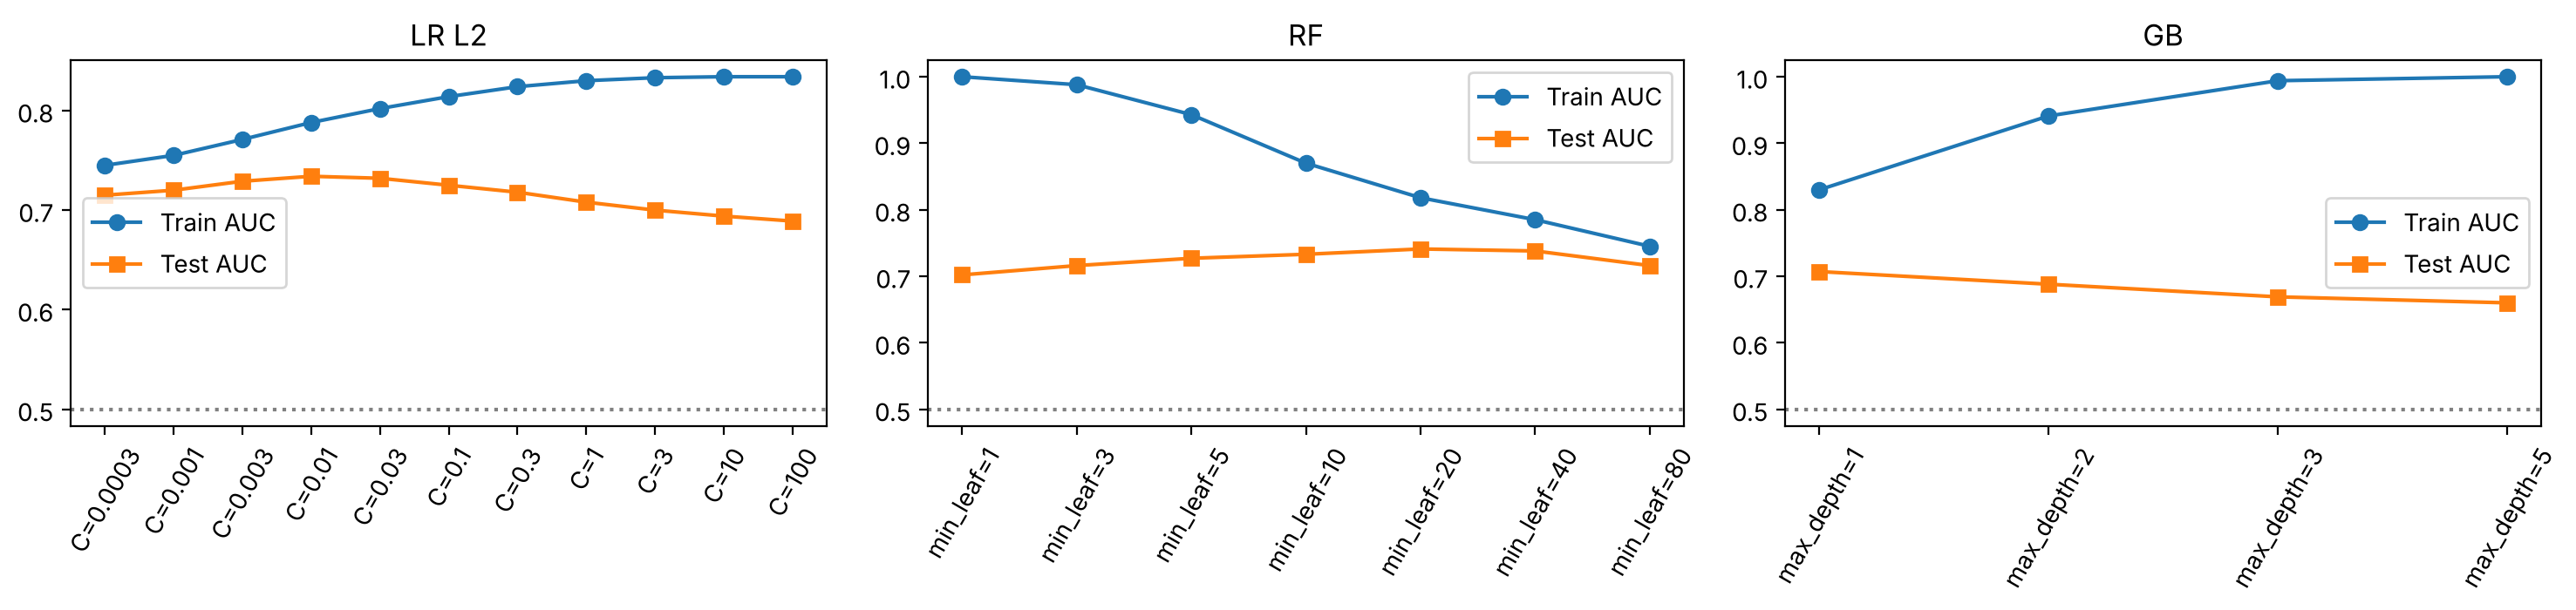

,model,param,Train_AUC,Test_AUC,Sens,Spec
0,LR L2,C=0.0003,0.745,0.715,0.542,0.795
1,LR L2,C=0.001,0.755,0.720,0.530,0.792
2,LR L2,C=0.003,0.771,0.729,0.542,0.764
3,LR L2,C=0.01,0.788,0.734,0.590,0.704
4,LR L2,C=0.03,0.802,0.732,0.627,0.680
5,LR L2,C=0.1,0.814,0.725,0.617,0.685
6,LR L2,C=0.3,0.824,0.718,0.602,0.684
7,LR L2,C=1,0.830,0.708,0.572,0.707
8,LR L2,C=3,0.833,0.700,0.537,0.724
9,LR L2,C=10,0.834,0.694,0.560,0.687


In [14]:
reg_rows = []
for C_ in [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]:
    r = nested_cv(make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced", C=C_)), None)
    reg_rows.append(dict(model="LR L2", param=f"C={C_}", Train_AUC=r.Train_AUC, Test_AUC=r.AUC, Sens=r.Sensitivity, Spec=r.Specificity))
for leaf in [1, 3, 5, 10, 20, 40, 80]:
    r = nested_cv(make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, class_weight="balanced", random_state=0, n_jobs=2)), None)
    reg_rows.append(dict(model="RF", param=f"min_leaf={leaf}", Train_AUC=r.Train_AUC, Test_AUC=r.AUC, Sens=r.Sensitivity, Spec=r.Specificity))
for depth in [1, 2, 3, 5]:
    r = nested_cv(make_pipe(GradientBoostingClassifier(n_estimators=150, max_depth=depth, learning_rate=0.05, subsample=0.8, random_state=0)), None)
    reg_rows.append(dict(model="GB", param=f"max_depth={depth}", Train_AUC=r.Train_AUC, Test_AUC=r.AUC, Sens=r.Sensitivity, Spec=r.Specificity))
res_reg = pd.DataFrame(reg_rows).round(3)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, m in zip(ax, ["LR L2", "RF", "GB"]):
    s = res_reg[res_reg.model == m]
    a.plot(s.param, s.Train_AUC, "o-", label="Train AUC"); a.plot(s.param, s.Test_AUC, "s-", label="Test AUC")
    a.set_title(m); a.tick_params(axis="x", rotation=60); a.axhline(0.5, ls=":", c="gray"); a.legend()
plt.tight_layout(); plt.show()
res_reg

## 10. Dimensionality reduction

Reduction steps are inside the pipeline; k and the number of components are tuned in the inner loop.

In [15]:
def mi_score(X_, y_): return mutual_info_classif(X_, y_, random_state=0)
LRr = LogisticRegression(max_iter=5000, class_weight="balanced")
gCr = {"model__C": [0.01, 0.1, 1]}
dr_cfg = {
    "No reduction (all features)":  (make_pipe(LRr), gCr),
    "PCA (components tuned)":       (make_pipe(LRr, reduce=PCA(random_state=0)), {**gCr, "reduce__n_components": [3, 5, 10, 20]}),
    "SelectKBest ANOVA F":          (make_pipe(LRr, reduce=SelectKBest(f_classif)), {**gCr, "reduce__k": [3, 5, 10, 20]}),
    "SelectKBest Mutual Info":      (make_pipe(LRr, reduce=SelectKBest(mi_score)), {**gCr, "reduce__k": [3, 5, 10, 20]}),
    "L1 selection → LR":            (make_pipe(LRr, reduce=SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced"))), {**gCr, "reduce__estimator__C": [0.05, 0.1, 0.5]}),
    "PCA → Random Forest":          (make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced", random_state=0, n_jobs=1), reduce=PCA(random_state=0)), {"reduce__n_components": [3, 5, 10]}),
}
res_dr = run_table(dr_cfg)
for name, feats in {"Baseline features only": BASE, "Early-AE features only": EARLY}.items():
    r = nested_cv(make_pipe(LRr, prep=make_prep(features=feats)), gCr, Xd=d[feats])
    res_dr.loc[name] = r[res_dr.columns].astype(float).round(3)
res_dr

No reduction (all features)              AUC=0.734  (6s)


PCA (components tuned)                   AUC=0.720  (11s)


SelectKBest ANOVA F                      AUC=0.744  (12s)


SelectKBest Mutual Info                  AUC=0.735  (60s)


L1 selection → LR                        AUC=0.730  (10s)


PCA → Random Forest                      AUC=0.693  (60s)


,AUC,AUC_sd,Train_AUC,PR_AUC,Accuracy,Sensitivity,Specificity,Precision,NPV,F1,F2,Brier
No reduction (all features),0.734,0.006,0.788,0.609,0.662,0.590,0.704,0.536,0.749,0.560,0.577,0.209
PCA (components tuned),0.720,0.016,0.763,0.600,0.646,0.629,0.655,0.514,0.754,0.565,0.602,0.210
SelectKBest ANOVA F,0.744,0.003,0.758,0.632,0.671,0.639,0.690,0.545,0.768,0.587,0.617,0.206
SelectKBest Mutual Info,0.735,0.006,0.764,0.612,0.659,0.657,0.661,0.530,0.772,0.584,0.624,0.211
L1 selection → LR,0.730,0.010,0.768,0.609,0.664,0.627,0.685,0.538,0.761,0.577,0.605,0.209
PCA → Random Forest,0.693,0.015,0.898,0.568,0.658,0.570,0.708,0.531,0.741,0.549,0.561,0.216
Baseline features only,0.675,0.009,0.741,0.517,0.679,0.654,0.693,0.551,0.776,0.598,0.631,0.228
Early-AE features only,0.682,0.014,0.736,0.586,0.679,0.527,0.766,0.565,0.737,0.546,0.535,0.219


## 11. Class imbalance

Resamplers act on training folds only; outer test folds are never resampled.

In [16]:
imb_cfg = {
    "No correction":         (make_pipe(LogisticRegression(max_iter=5000)), gC),
    "class_weight balanced": (make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced")), gC),
    "SMOTE":                 (make_pipe(LogisticRegression(max_iter=5000), sampler=SMOTE(random_state=0)), {**gC, "sampler__k_neighbors": [3, 5]}),
    "Random Over-Sampling":  (make_pipe(LogisticRegression(max_iter=5000), sampler=RandomOverSampler(random_state=0)), gC),
    "Random Under-Sampling": (make_pipe(LogisticRegression(max_iter=5000), sampler=RandomUnderSampler(random_state=0)), gC),
    "SMOTE + Random Forest": (make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=0, n_jobs=1), sampler=SMOTE(random_state=0)), None),
}
res_imb = run_table(imb_cfg)
res_imb

No correction                            AUC=0.729  (5s)


class_weight balanced                    AUC=0.734  (4s)


SMOTE                                    AUC=0.730  (7s)


Random Over-Sampling                     AUC=0.734  (5s)


Random Under-Sampling                    AUC=0.730  (5s)


SMOTE + Random Forest                    AUC=0.731  (24s)


,AUC,AUC_sd,Train_AUC,PR_AUC,Accuracy,Sensitivity,Specificity,Precision,NPV,F1,F2,Brier
No correction,0.729,0.007,0.787,0.602,0.665,0.565,0.723,0.543,0.743,0.551,0.558,0.198
class_weight balanced,0.734,0.006,0.788,0.609,0.662,0.590,0.704,0.536,0.749,0.560,0.577,0.209
SMOTE,0.730,0.008,0.787,0.609,0.655,0.627,0.671,0.525,0.758,0.569,0.602,0.209
Random Over-Sampling,0.734,0.011,0.789,0.605,0.676,0.592,0.724,0.558,0.757,0.570,0.582,0.208
Random Under-Sampling,0.730,0.009,0.780,0.617,0.669,0.567,0.728,0.547,0.746,0.555,0.562,0.212
SMOTE + Random Forest,0.731,0.012,0.883,0.628,0.664,0.627,0.685,0.536,0.760,0.578,0.606,0.201


## 12. Validation strategies

Same learner (L2 LR, C grid) under four evaluation schemes.

In [17]:
val_rows = []
gridC = {"model__C": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]}
pipe_lr = make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced"))
for s in SEEDS:
    gs = GridSearchCV(clone(pipe_lr), gridC, cv=StratifiedKFold(N_OUTER, shuffle=True, random_state=s), scoring="roc_auc", n_jobs=2).fit(X, y)
    val_rows.append(dict(method="1) Non-nested: tuned and scored on the same folds", seed=s, AUC=gs.best_score_))
for s in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
    gs = GridSearchCV(clone(pipe_lr), gridC, cv=StratifiedKFold(N_INNER, shuffle=True, random_state=s), scoring="roc_auc", n_jobs=2).fit(Xtr, ytr)
    val_rows.append(dict(method="2) Hold-out 80/20 (10 splits)", seed=s, AUC=roc_auc_score(yte, gs.predict_proba(Xte)[:, 1])))
r = nested_cv(pipe_lr, gridC, seeds=[SEEDS[0]]); val_rows.append(dict(method="3) Nested CV (one seed)", seed=SEEDS[0], AUC=r.AUC))
r = nested_cv(pipe_lr, gridC);              val_rows.append(dict(method="4) Repeated nested CV (3 seeds)", seed=-1, AUC=r.AUC))
res_val = pd.DataFrame(val_rows).groupby("method").AUC.agg(["mean", "std", "min", "max", "count"]).round(3)
res_val

,mean,std,min,max,count
method,,,,,
1) Non-nested: tuned and scored on the same folds,0.736,0.004,0.731,0.738,3
2) Hold-out 80/20 (10 splits),0.708,0.057,0.615,0.785,10
3) Nested CV (one seed),0.713,NaN,0.713,0.713,1
4) Repeated nested CV (3 seeds),0.725,NaN,0.725,0.725,1


## 13. Nested model selection (primary estimate)

Six pre-specified families in one inner grid search, so the family choice is also nested.

In [18]:
cand_grid = [
    {"model": [LogisticRegression(max_iter=5000, class_weight="balanced")], "model__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1]},
    {"model": [LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced")], "model__C": [0.05, 0.1, 0.5]},
    {"model": [RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0, n_jobs=1)], "model__min_samples_leaf": [10, 20, 40]},
    {"model": [GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, subsample=0.8, random_state=0)], "model__max_depth": [1, 2]},
    {"model": [SVC(probability=True, class_weight="balanced", random_state=0)], "model__C": [0.1, 1]},
    {"model": [VotingClassifier([("lr", lr_), ("rf", rf_), ("gb", gb_)], voting="soft")]},
]
final_pipe = make_pipe(LogisticRegression())
final_sum, final_detail = nested_cv(final_pipe, cand_grid, return_detail=True)
print("Nested model selection (mean of 3 seeds):")
final_sum[["AUC", "AUC_sd", "PR_AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2", "Brier"]].astype(float).round(3)

Nested model selection (mean of 3 seeds):


AUC            0.737
AUC_sd         0.002
PR_AUC         0.611
Accuracy       0.665
Sensitivity    0.692
Specificity    0.649
Precision      0.533
NPV            0.786
F1             0.601
F2             0.652
Brier          0.211
dtype: float64

### 13.1 Confusion matrices and bootstrap intervals (1,000 resamples of the seed-42 out-of-fold predictions)

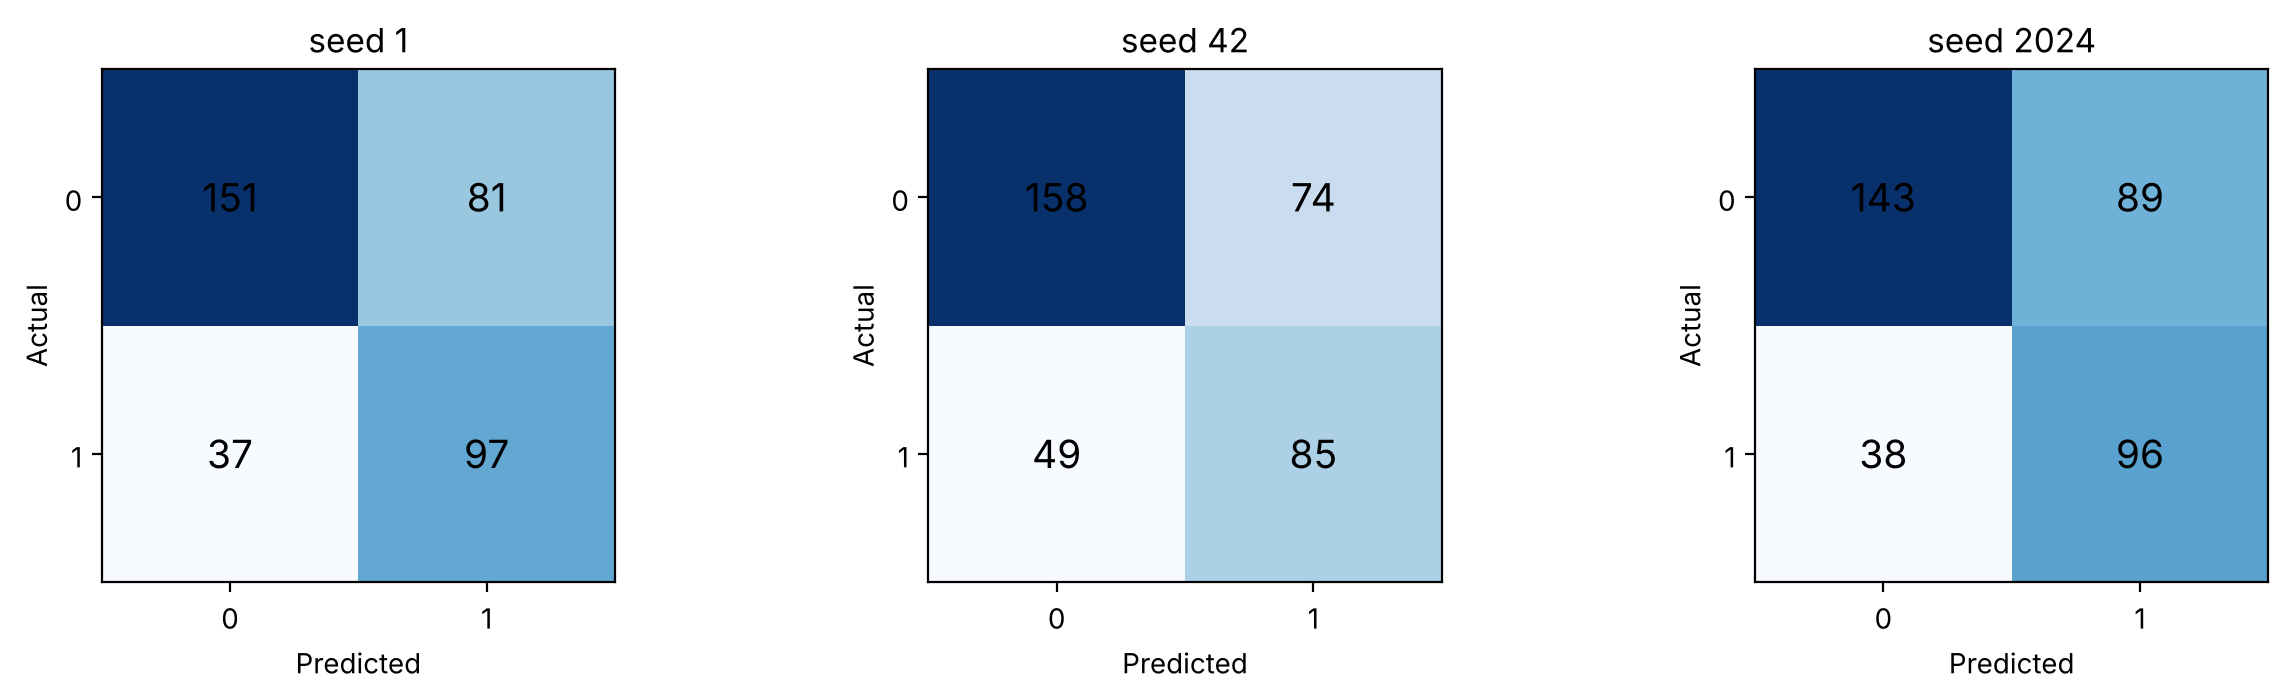

Confusion matrix (seed 42):
 [[158  74]
 [ 49  85]]


Bootstrap 95% CI (seed 42): {'AUC': array([0.684, 0.787]), 'Sensitivity': array([0.556, 0.712]), 'Specificity': array([0.618, 0.739])}


In [19]:
rng = np.random.default_rng(0)
def boot_ci(y_, p_, pr_, B=1000):
    out = {"AUC": [], "Sensitivity": [], "Specificity": []}
    for _ in range(B):
        i = rng.integers(0, len(y_), len(y_))
        if y_[i].min() == y_[i].max(): continue
        m = metrics(y_[i], p_[i], pr_[i])
        for k in out: out[k].append(m[k])
    return {k: np.percentile(v, [2.5, 97.5]).round(3) for k, v in out.items()}

fig, ax = plt.subplots(1, len(SEEDS), figsize=(4.2 * len(SEEDS), 3.6))
for a, s, det in zip(ax, SEEDS, final_detail):
    cm = confusion_matrix(y, det["pred"])
    a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center", fontsize=14)
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xlabel("Predicted"); a.set_ylabel("Actual"); a.set_title(f"seed {s}")
plt.tight_layout(); plt.show()
det = final_detail[1]
print("Confusion matrix (seed 42):\n", confusion_matrix(y, det["pred"]))
print("Bootstrap 95% CI (seed 42):", boot_ci(y, det["prob"], det["pred"]))

### 13.2 Family selected in each outer fold

In [20]:
picks = []
for s in SEEDS:
    for tr, te in StratifiedKFold(N_OUTER, shuffle=True, random_state=s).split(X, y):
        gs = GridSearchCV(clone(final_pipe), cand_grid, cv=StratifiedKFold(N_INNER, shuffle=True, random_state=s), scoring="roc_auc", n_jobs=2).fit(X.iloc[tr], y[tr])
        mdl = gs.best_params_["model"]
        picks.append(type(mdl).__name__ + ("-L1" if getattr(mdl, "penalty", "") == "l1" else ""))
pd.Series(picks).value_counts()

RandomForestClassifier    7
LogisticRegression-L1     6
LogisticRegression        2
Name: count, dtype: int64

## 14. Threshold rules

Applied to the best single configuration from Sections 7–8; every rule is chosen on inner folds. The fixed-threshold table uses the seed-42 nested-selection probabilities and is descriptive only.

In [21]:
best_overall = res_simple.AUC.idxmax() if res_simple.AUC.max() >= res_ens.AUC.max() else res_ens.AUC.idxmax()
cfg_all = {**simple_cfg, **ens_cfg}
print("Configuration used below:", best_overall)
thr_rows = {}
for rule_ in ["youden", "f2", "f1", "sens80", "acc"]:
    thr_rows[rule_] = nested_cv(*cfg_all[best_overall], rule=rule_)
res_thr = pd.DataFrame(thr_rows).T[["AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2"]].astype(float).round(3)
display(res_thr)
fixed = []
p_ = final_detail[1]["prob"]
for t_ in np.arange(0.2, 0.81, 0.05):
    m = metrics(y, p_, (p_ >= t_).astype(int)); m["threshold"] = round(t_, 2); fixed.append(m)
pd.DataFrame(fixed).set_index("threshold")[["Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2", "Accuracy", "TP", "FP", "FN", "TN"]].round(3)

Configuration used below: Random Forest


,AUC,Accuracy,Sensitivity,Specificity,Precision,NPV,F1,F2
youden,0.738,0.646,0.664,0.635,0.512,0.767,0.578,0.627
f2,0.738,0.465,0.940,0.191,0.402,0.847,0.563,0.741
f1,0.738,0.637,0.751,0.570,0.503,0.800,0.602,0.683
sens80,0.738,0.638,0.813,0.537,0.504,0.833,0.622,0.724
acc,0.738,0.712,0.430,0.875,0.667,0.727,0.522,0.463


,Sensitivity,Specificity,Precision,NPV,F1,F2,Accuracy,TP,FP,FN,TN
threshold,,,,,,,,,,,
0.20,1.000,0.000,0.366,0.000,0.536,0.743,0.366,134,232,0,0
0.25,1.000,0.000,0.366,0.000,0.536,0.743,0.366,134,232,0,0
0.30,0.985,0.082,0.383,0.905,0.551,0.749,0.413,132,213,2,19
0.35,0.888,0.284,0.418,0.815,0.568,0.725,0.505,119,166,15,66
0.40,0.806,0.483,0.474,0.812,0.597,0.707,0.601,108,120,26,112
0.45,0.731,0.616,0.524,0.799,0.611,0.678,0.658,98,89,36,143
0.50,0.634,0.698,0.548,0.768,0.588,0.615,0.675,85,70,49,162
0.55,0.552,0.797,0.612,0.755,0.580,0.563,0.708,74,47,60,185
0.60,0.433,0.892,0.699,0.731,0.535,0.468,0.724,58,25,76,207


## 15. Calibration

Platt scaling wraps the whole pipeline and is tuned inside the inner loop.

,Raw,Platt
AUC,0.738,0.742
Brier,0.209,0.193
Calibration slope,1.219,1.027


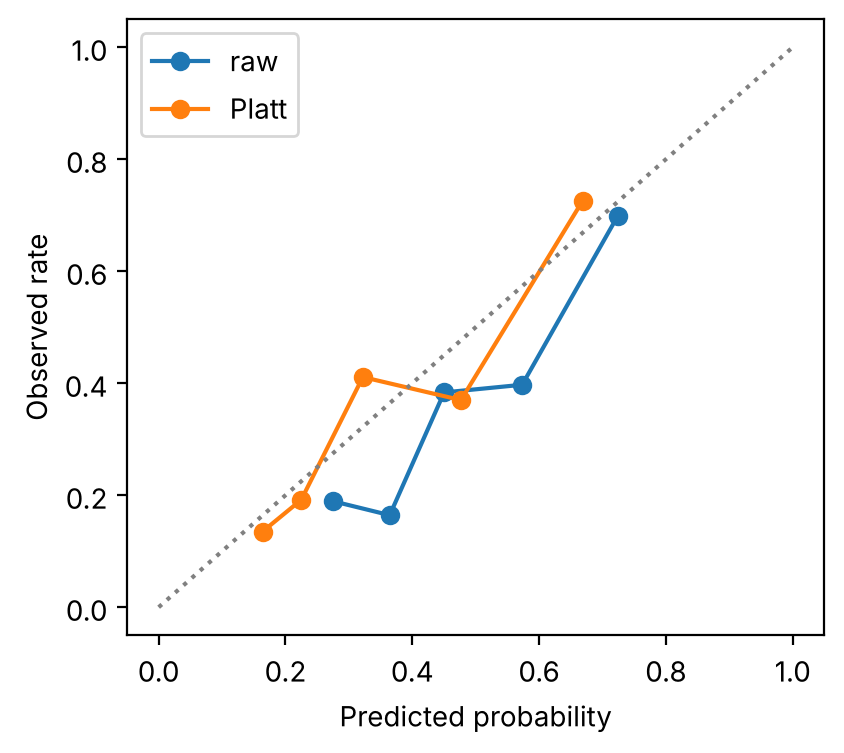

In [22]:
def cal_slope(y_, p_):
    lp = np.log(np.clip(p_, 1e-6, 1 - 1e-6) / (1 - np.clip(p_, 1e-6, 1 - 1e-6)))
    return LogisticRegression(C=1e6).fit(lp.reshape(-1, 1), y_).coef_[0][0]
base_pipe, base_grid = cfg_all[best_overall]
raw_s, raw_d = nested_cv(base_pipe, base_grid, return_detail=True)
plat_pipe = CalibratedClassifierCV(clone(base_pipe), cv=4, method="sigmoid")
plat_grid = {"estimator__" + k: v for k, v in base_grid.items()} if base_grid else None
pl_s, pl_d = nested_cv(plat_pipe, plat_grid, return_detail=True)
cal = pd.DataFrame({"Raw": [raw_s.AUC, raw_s.Brier, cal_slope(y, raw_d[1]["prob"])],
                    "Platt": [pl_s.AUC, pl_s.Brier, cal_slope(y, pl_d[1]["prob"])]},
                   index=["AUC", "Brier", "Calibration slope"]).round(3)
display(cal)
fig, a = plt.subplots(figsize=(4.5, 4))
for lab, p_ in [("raw", raw_d[1]["prob"]), ("Platt", pl_d[1]["prob"])]:
    bins = pd.qcut(p_, 5, duplicates="drop")
    g = pd.DataFrame({"p": p_, "y": y}).groupby(bins, observed=True).mean()
    a.plot(g.p, g.y, "o-", label=lab)
a.plot([0, 1], [0, 1], ":", c="gray"); a.set_xlabel("Predicted probability"); a.set_ylabel("Observed rate"); a.legend(); plt.show()

## 16. Risk tiers

Tertile cut-points come from inner out-of-fold probabilities of each training fold.

In [23]:
tiers = []
for s, det in zip(SEEDS, final_detail):
    t_ = pd.DataFrame({"tier": pd.Series(det["tert"]).map({0: "1-low", 1: "2-intermediate", 2: "3-high"}), "y": y})
    g = t_.groupby("tier").y.agg(["size", "sum", "mean"]); g["seed"] = s; tiers.append(g)
tiers = pd.concat(tiers).reset_index().groupby("tier")[["size", "sum", "mean"]].mean().round(3)
tiers.columns = ["mean n", "mean events", "event rate"]
tiers

,mean n,mean events,event rate
tier,,,
1-low,129.667,21.667,0.167
2-intermediate,112.667,38.667,0.343
3-high,123.667,73.667,0.596


## 17. Subgroups (seed 42, nested selection; groups with < 15 patients or one class are skipped)

In [24]:
det = final_detail[1]
sub_rows = []
groups = {"Arm (indrx)": d.indrx, "Carboplatin": d.carbo.map({0: "no", 1: "yes"}), "Age group (AGE_C)": d.AGE_C,
          "White (WHITE)": d.WHITE, "ER": d.er, "Stage (stra1_stage)": d.stra1_stage}
for gname, col in groups.items():
    for lvl in sorted(col.dropna().unique()):
        k = (col == lvl).values
        if k.sum() < 15 or y[k].min() == y[k].max(): continue
        m = metrics(y[k], det["prob"][k], det["pred"][k])
        sub_rows.append(dict(group=gname, level=lvl, n=int(k.sum()), events=int(y[k].sum()), AUC=m["AUC"], Sensitivity=m["Sensitivity"], Specificity=m["Specificity"], F2=m["F2"]))
pd.DataFrame(sub_rows).round(3)

,group,level,n,events,AUC,Sensitivity,Specificity,F2
0,Arm (indrx),1,102,20,0.669,0.200,0.890,0.215
1,Arm (indrx),2,104,24,0.507,0.125,0.888,0.139
2,Arm (indrx),3,77,37,0.700,0.811,0.275,0.725
3,Arm (indrx),4,83,53,0.607,0.906,0.100,0.836
4,Carboplatin,no,206,44,0.590,0.159,0.889,0.174
5,Carboplatin,yes,160,90,0.676,0.867,0.200,0.789
6,Age group (AGE_C),1,85,26,0.756,0.615,0.695,0.580
7,Age group (AGE_C),2,221,83,0.765,0.663,0.703,0.643
8,Age group (AGE_C),3,60,25,0.582,0.560,0.571,0.543
9,White (WHITE),1,265,94,0.730,0.628,0.649,0.596


## 18. Permutation importance (held-out folds, seed 42) and Mann–Whitney test (descriptive)

In [25]:
imp = []
bp, bg = cfg_all[best_overall]
for tr, te in StratifiedKFold(N_OUTER, shuffle=True, random_state=42).split(X, y):
    m_ = (GridSearchCV(clone(bp), bg, cv=StratifiedKFold(N_INNER, shuffle=True, random_state=42), scoring="roc_auc").fit(X.iloc[tr], y[tr]).best_estimator_
          if bg else clone(bp).fit(X.iloc[tr], y[tr]))
    r = permutation_importance(m_, X.iloc[te], y[te], scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=2)
    imp.append(r.importances_mean)
imp = pd.DataFrame({"importance (AUC drop)": np.mean(imp, 0)}, index=FEATURES).sort_values("importance (AUC drop)", ascending=False)
top = imp.head(10).copy()
top["Mann-Whitney p"] = [mannwhitneyu(X[c][y == 1].dropna(), X[c][y == 0].dropna()).pvalue for c in top.index]
top.round(4)

,importance (AUC drop),Mann-Whitney p
factora,0.0446,0.0000
indrx,0.0166,0.0000
e_max_pain,0.0122,0.4588
e_count_g2,0.0085,0.0000
e_first_day,0.0063,0.4340
e_max_thrombocytopenia_h,0.0057,0.0000
e_max_thrombocytopenia,0.0039,0.0000
e_max_neutropenia_h,0.0036,0.0000
e_max_gi,0.0015,0.0005
e_max_neutropenia,0.0012,0.0000


## 19. Robustness on five unseen seeds

In [26]:
rob = []
for s in ROB_SEEDS:
    r = nested_cv(*cfg_all[best_overall], seeds=[s]); r["seed"] = s; rob.append(r)
rob = pd.DataFrame(rob).set_index("seed")[["AUC", "Sensitivity", "Specificity", "F1", "F2", "Accuracy"]].astype(float)
rob.loc["mean"] = rob.mean(); rob.loc["sd"] = rob.iloc[:-1].std()
rob.round(3)

,AUC,Sensitivity,Specificity,F1,F2,Accuracy
seed,,,,,,
7.0,0.718,0.604,0.681,0.561,0.586,0.653
99.0,0.743,0.619,0.703,0.580,0.603,0.672
314.0,0.737,0.672,0.651,0.590,0.636,0.658
777.0,0.728,0.649,0.711,0.604,0.630,0.689
2025.0,0.731,0.716,0.655,0.619,0.674,0.678
mean,0.731,0.652,0.680,0.591,0.626,0.670
sd,0.009,0.044,0.027,0.022,0.034,0.014


## 20. Summary

Per-family best values are optimistic (chosen after the fact); the primary estimate is the nested-selection row.

In [27]:
summary = pd.DataFrame({
    "Arm only": arm_only,
    rule_name: rule_m,
    "Best preprocessing: " + res_prep.AUC.idxmax(): res_prep.loc[res_prep.AUC.idxmax()],
    "Best simple: " + res_simple.AUC.idxmax(): res_simple.loc[res_simple.AUC.idxmax()],
    "Best ensemble: " + res_ens.AUC.idxmax(): res_ens.loc[res_ens.AUC.idxmax()],
    "Best reduction: " + res_dr.AUC.idxmax(): res_dr.loc[res_dr.AUC.idxmax()],
    "Best imbalance: " + res_imb.AUC.idxmax(): res_imb.loc[res_imb.AUC.idxmax()],
    "Final (nested selection)": final_sum,
}).T[["AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "F1", "F2"]].astype(float).round(3)
summary.to_csv(f"summary_{TARGET}.csv")
for name, df_ in {"prep": res_prep, "simple": res_simple, "ens": res_ens, "reg": res_reg, "dr": res_dr, "imb": res_imb, "thr": res_thr, "tiers": tiers, "cal": cal}.items():
    df_.to_csv(f"res_{TARGET}_{name}.csv")
res_val.to_csv(f"res_{TARGET}_val.csv"); top.to_csv(f"res_{TARGET}_imp.csv"); rob.to_csv(f"res_{TARGET}_rob.csv"); pd.DataFrame(sub_rows).to_csv(f"res_{TARGET}_sub.csv", index=False)
pd.Series(picks).value_counts().to_csv(f"res_{TARGET}_picks.csv")
print(f"Total run time: {(time.time()-T0)/60:.1f} min")
summary

Total run time: 42.0 min


,AUC,Accuracy,Sensitivity,Specificity,Precision,F1,F2
Arm only,0.683,0.689,0.672,0.698,0.562,0.612,0.647
Rule: ANC or platelet grade >=1 by day 28,0.656,0.694,0.515,0.797,0.595,0.552,0.529
Best preprocessing: median + ordinal categories,0.737,0.661,0.659,0.662,0.532,0.586,0.627
Best simple: LR L1 (Lasso),0.733,0.670,0.667,0.672,0.542,0.594,0.635
Best ensemble: Random Forest,0.738,0.646,0.664,0.635,0.512,0.578,0.627
Best reduction: SelectKBest ANOVA F,0.744,0.671,0.639,0.690,0.545,0.587,0.617
Best imbalance: class_weight balanced,0.734,0.662,0.590,0.704,0.536,0.560,0.577
Final (nested selection),0.737,0.665,0.692,0.649,0.533,0.601,0.652
